# 40 · Where the cost lies

**Question.** Is the standard form's cost in its encoder or in its Hamiltonian, and what does the descriptor form change?

In [1]:
from pathlib import Path

from pihm import plotting
from pihm.pipeline.results import Results

results = Results.at(Path("..").resolve())
CAMPAIGNS = ("p5_encoders", "p5_t3", "p2_reproduction", "p5_build", "p5_stateprep")
plotting.apply_style()
print(results.describe(CAMPAIGNS))

p5_encoders: 14 records, 14 ok
p5_t3: 192 records, 192 ok
p2_reproduction: 327 records, 327 ok
p5_build: 224 records, 224 ok
p5_stateprep: 338 records, 338 ok


In [2]:
from IPython.display import Markdown, display

from pihm.pipeline.results import degree_exponents, encoding_scaling, primary_preparations
from pihm.pipeline.summary import encoder_of

standard_builds, descriptor_builds = results.rows("p2_reproduction"), results.rows("p5_build")
encoders = results.rows("p5_encoders")
headline = encoding_scaling(
    {
        "structured": (
            [r for r in encoders if encoder_of(r) == "structured"],
            standard_builds,
            primary_preparations(results.rows("p5_stateprep", regime="standard")),
        ),
        "published": ([r for r in encoders if encoder_of(r) == "published"], standard_builds, []),
        "descriptor": (
            results.rows("p5_t3", regime="descriptor"),
            descriptor_builds,
            primary_preparations(results.rows("p5_stateprep", regime="descriptor")),
        ),
    },
    problem="R2a",
    variant="corrected",
)
resolved = sorted({r["n"] for r in headline} - {r["n"] for r in headline if not r["trusted"]})
degree = {row["encoding"]: row["exponent"] for row in degree_exponents(headline, resolved)}
cx = {row["encoding"]: row["exponent"] for row in degree_exponents(headline, resolved, "cx")}
top = {row["encoding"]: row for row in headline if row["n"] == resolved[-1]}

panels = encoding_scaling(
    {
        "structured": (results.rows("p5_t3", regime="standard"), standard_builds, []),
        "descriptor": (results.rows("p5_t3", regime="descriptor"), descriptor_builds, []),
    },
    variant="corrected",
)


def common(column):
    """Return the values of a column that both forms' rows share."""
    return {r[column] for r in panels if r["encoding"] == "structured"} & {
        r[column] for r in panels if r["encoding"] == "descriptor"
    }


problems, shared = common("problem"), sorted(common("n"))
panels = [r for r in panels if r["problem"] in problems]
fits = degree_exponents([r for r in panels if r["trusted"]], shared)


def spread(encoding):
    """Return the range of an encoding's exponents over the panels, and the panels left out."""
    values = [f["exponent"] for f in fits if f["encoding"] == encoding]
    fitted = {f["problem"] for f in fits if f["encoding"] == encoding}
    missing = sorted({r["problem"] for r in panels} - fitted)
    return f"{min(values):.1f} to {max(values):.1f}", ", ".join(missing) or "none"


display(
    Markdown(
        f"""R2a (Fig. 3b), fitted over n = {resolved[0]} to {resolved[-1]}, where every reference is
trusted:

- The degree grows as N^{degree["published"]:.1f} with the published encoding,
  N^{degree["structured"]:.1f} with the structured one and N^{degree["descriptor"]:.1f} in the
  descriptor form; the total cx as N^{cx["published"]:.1f}, N^{cx["structured"]:.1f} and
  N^{cx["descriptor"]:.1f}.
- At n = {resolved[-1]}, the encoding: α_H/‖H‖ is {top["published"]["looseness"]:.2g} published,
  {top["structured"]["looseness"]:.3g} structured and {top["descriptor"]["looseness"]:.3g} in the
  descriptor.
- The Hamiltonian: the relative gap Δ/‖H‖ is {top["structured"]["relative_gap"]:.2g} in the
  standard form and {top["descriptor"]["relative_gap"]:.2g} in the descriptor.
- The degree: {top["published"]["degree"]:.2g}, {top["structured"]["degree"]:.2g} and
  {top["descriptor"]["degree"]:.2g}.

Every corrected panel, fitted where its references are trusted: the degree's exponent is
{spread("structured")[0]} in the standard form (too few trusted resolutions:
{spread("structured")[1]}) and {spread("descriptor")[0]} in the descriptor (too few:
{spread("descriptor")[1]})."""
    )
)

R2a (Fig. 3b), fitted over n = 3 to 8, where every reference is
trusted:

- The degree grows as N^10.1 with the published encoding,
  N^4.1 with the structured one and N^0.8 in the
  descriptor form; the total cx as N^10.3, N^4.4 and
  N^1.0.
- At n = 8, the encoding: α_H/‖H‖ is 3.7e+27 published,
  59.9 structured and 1.09 in the
  descriptor.
- The Hamiltonian: the relative gap Δ/‖H‖ is 2.3e-17 in the
  standard form and 6.9e-07 in the descriptor.
- The degree: 9.1e+22, 1.2e+10 and
  9.1e+03.

Every corrected panel, fitted where its references are trusted: the degree's exponent is
2.0 to 4.1 in the standard form (too few trusted resolutions:
R5c) and 0.5 to 3.3 in the descriptor (too few:
R5c).

R2a against N: the encoding's looseness, the Hamiltonian's relative gap, and the filter's degree,
which grows as the square root of their ratio. Estimates are T3's; crosses mark
T2's measured degree.

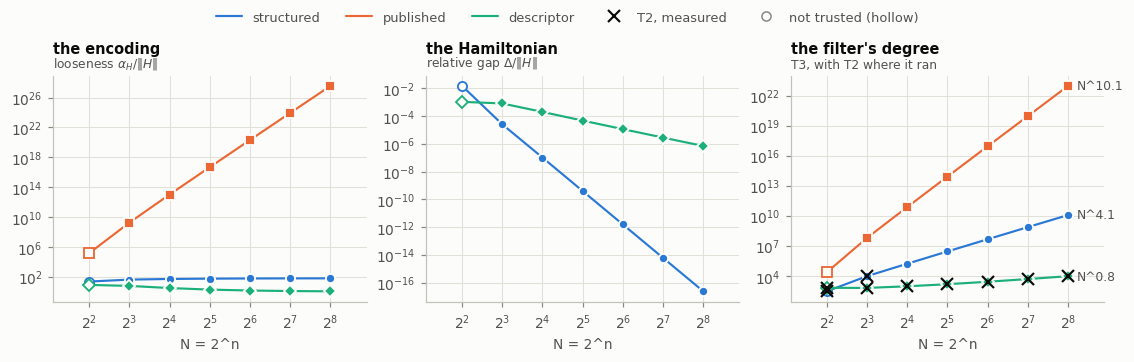

In [3]:
plotting.cost_walls(headline, degree_exponents(headline, resolved));

Every corrected panel: the degree's fitted exponent in N, in both forms, over the resolutions both
forms' T3 campaigns estimated and whose reference is trusted. On one axis, the expected exponent is
about 4 in the standard form and 1 in the descriptor where the leading coefficient has no zero, and
about 2 in the descriptor where it vanishes simply or on two axes.

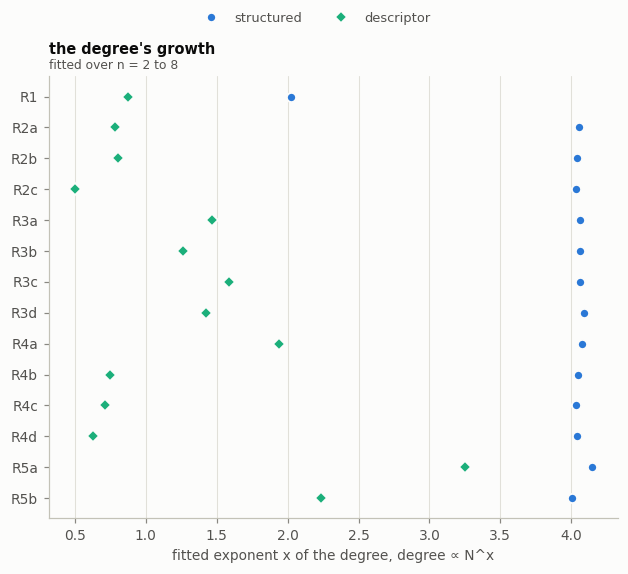

In [4]:
plotting.exponent_dots(fits);

**What this does not show.** These are resource estimates, under the minimax filter in both forms.
The published encoding is this library's build of the paper's Fig. 9 circuit, whose α is below the
paper's printed prefactor, so its column is the kinder one. Two-axis panels fit over the resolution per
axis.